# تحلیل اکتشافی: زمان بستن شکایت‌های نویز ۳۱۱ نیویورک

**سؤال:** یک شکایت نویز چقدر طول می‌کشد تا بسته شود، و این زمان به نوع شکایت، محله و زمان ثبت چطور بستگی دارد؟

تمام محاسبه‌ها در `data_factory.analysis` است و این نوت‌بوک فقط آن‌ها را صدا می‌زند و نتیجه را روایت می‌کند.
هر عددی که در متن آمده از خروجی همین نوت‌بوک قابل ردیابی است.

## ۰. اجرای کارخانه و شواهد مهندسی

اگر خروجی‌های `data/curated/` موجود نباشند، کارخانه با `python -m data_factory run` اجرا می‌شود (روی clone تازه شامل دانلود حدود ۱٫۰۸ میلیون رکورد است).
عددهای گزارش (تعداد خام، قرنطینه، join، بودجه‌ی درخواست) از `run_manifest.json` همین اجرا خوانده و در همین بخش چاپ می‌شوند.

In [1]:
import subprocess
import sys
from pathlib import Path

CASES = Path("data/curated/cases.csv")
if not CASES.is_file():
    proc = subprocess.run(
        [sys.executable, "-m", "data_factory", "run"],
        capture_output=True, text=True, check=False,
    )
    print(proc.stdout[-2000:])
    print(proc.stderr[-2000:])
    proc.check_returncode()
CASES.is_file()

pages_total=22 pages_fetched=22 rows_fetched=1083411 resumed_from_page=0 requests=23 dir=data/raw/6062794455d0
reference_rows=178 requests=24 path=data/raw/reference/modzcta.json
window=2025-01-01..2026-06-30 total=1083411 passed=1083410 quarantined=1 matched=1082875 missing_zip=79 unmatched_zip=456 top_unmatched=[('11001', 95), ('10000', 73), ('11040', 44), ('11359', 38), ('10154', 28)] ambiguous=876 requests=24 manifest=data/run_manifest.json




True

In [2]:
import hashlib
import json

from data_factory.config import load_config

cfg = load_config("config/default.toml")
manifest = json.loads(Path(cfg.paths.manifest_path).read_text(encoding="utf-8"))
keys = ("code_version", "window", "restriction", "records", "join", "request_budget", "requests_this_run")
print(json.dumps({k: manifest[k] for k in keys}, indent=2, ensure_ascii=False))

{
  "code_version": "0.1.0",
  "window": {
    "end_date": "2026-06-30",
    "start_date": "2025-01-01",
    "timezone": "America/New_York"
  },
  "restriction": {
    "agency": "NYPD",
    "complaint_types": [
      "Noise - Residential",
      "Noise - Street/Sidewalk",
      "Noise - Commercial",
      "Noise - Vehicle",
      "Noise - Park",
      "Noise - House of Worship"
    ]
  },
  "records": {
    "passed": 1083410,
    "quarantined": 1,
    "quarantined_by_reason": {
      "CLOSED_WITHOUT_CLOSED_DATE": 1
    },
    "raw": 1083411
  },
  "join": {
    "ambiguous_timestamps": 876,
    "matched": 1082875,
    "missing_zip": 79,
    "rows_in": 1083410,
    "rows_out": 1083410,
    "unmatched_distinct_zips": 39,
    "unmatched_zip": 456
  },
  "request_budget": {
    "case_requests_total": 23,
    "max_page_size_allowed": 50000,
    "minimum_case_requests": 22,
    "page_size": 50000,
    "raw_records": 1083411
  },
  "requests_this_run": 24
}


In [3]:
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


{name: sha256(info["path"]) == info["sha256"] for name, info in manifest["outputs"].items()}

{'dataset': True,
 'quality_report': True,
 'quarantine': True,
 'wide_table': True}

In [4]:
quality = json.loads(Path("data/curated/data_quality_report.json").read_text(encoding="utf-8"))
print(json.dumps(quality, indent=1, ensure_ascii=False)[:2500])

{
 "borough_modzcta_conflict_count": 5,
 "borough_modzcta_conflicts": [
  {
   "boroughs": [
    "BROOKLYN",
    "QUEENS",
    "Unspecified"
   ],
   "modzcta": "11416"
  },
  {
   "boroughs": [
    "BROOKLYN",
    "QUEENS",
    "Unspecified"
   ],
   "modzcta": "11208"
  },
  {
   "boroughs": [
    "BROOKLYN",
    "Unspecified"
   ],
   "modzcta": "11237"
  },
  {
   "boroughs": [
    "BROOKLYN",
    "QUEENS"
   ],
   "modzcta": "11385"
  },
  {
   "boroughs": [
    "BRONX",
    "MANHATTAN",
    "Unspecified"
   ],
   "modzcta": "10463"
  }
 ],
 "columns": {
  "agency": {
   "distinct_capped": false,
   "distinct_values": 1,
   "max": "NYPD",
   "min": "NYPD",
   "null_count": 0,
   "null_percent": 0.0,
   "rows": 1083410
  },
  "borough": {
   "distinct_capped": false,
   "distinct_values": 6,
   "max": "Unspecified",
   "min": "BRONX",
   "null_count": 0,
   "null_percent": 0.0,
   "rows": 1083410
  },
  "closed_at": {
   "distinct_capped": true,
   "distinct_values": null,
   "max"

In [5]:
RERUN_CHECK = True  # یک بار True کن، اجرا کن و خروجی را ذخیره کن؛ چند دقیقه طول می‌کشد
if RERUN_CHECK:
    first = {n: i["sha256"] for n, i in manifest["outputs"].items()}
    subprocess.run([sys.executable, "-m", "data_factory", "run"], check=True, capture_output=True, text=True)
    again = json.loads(Path(cfg.paths.manifest_path).read_text(encoding="utf-8"))
    second = {n: i["sha256"] for n, i in again["outputs"].items()}
    print({"requests_second_run": again["requests_this_run"], "hashes": "SAME" if first == second else "DIFFERENT"})

{'requests_second_run': 0, 'hashes': 'SAME'}


In [6]:
from pathlib import Path

from data_factory import analysis as a

SEED = a.SEED
df = a.load_cases(Path("data/curated/cases.csv"))
df.shape

(1083410, 12)

## ۱. توزیع مدت زمان تا بسته‌شدن

**چه چیزی را می‌سنجیم:** شکل توزیع مدت (ساعت) و اینکه کدام شاخص مرکزی معنادار است.

In [7]:
a.duration_summary(df).round(3)

count    1083410.000
mean           2.600
std            9.178
min            0.001
50%            1.094
75%            2.677
90%            5.972
95%            9.689
99%           20.905
max         1929.202
Name: duration_hours, dtype: float64

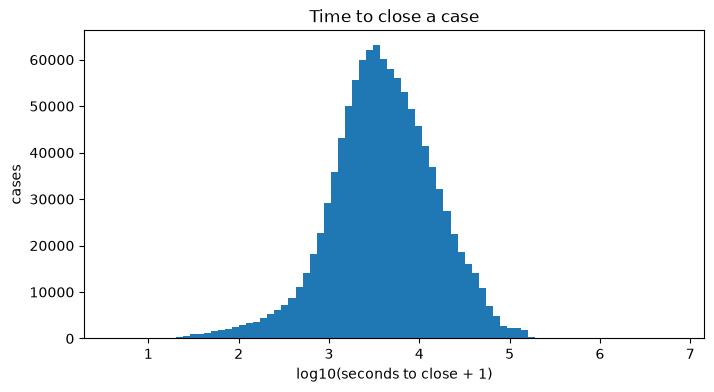

In [8]:
_ = a.plot_duration_histogram(df)

**نتیجه:** توزیع به‌شدت راست‌چوله است. میانه حدود ۱٫۰۹ ساعت است، ولی میانگین حدود ۲٫۶ ساعت است و بیشینه به ۱۹۲۹ ساعت می‌رسد.
پس میانگین را برای گزارش مرکز توزیع به کار نمی‌بریم و از **میانه** و مقیاس لگاریتمی استفاده می‌کنیم.

## ۲. شناسایی و تعیین تکلیف Outlier

**روش:** حصار Tukey روی `log1p(ساعت)`، چون روی مقیاس خام، دم بلند توزیع تقریباً همه را پرت می‌کند.

In [9]:
fences = a.tukey_fences(df["duration_hours"])
fences["share_above"] = round(fences["above"] / fences["total"], 4)
fences

{'low_hours': -0.6180106000888427,
 'high_hours': 13.308727557250661,
 'below': 0,
 'above': 29211,
 'total': 1083410,
 'share_above': 0.027}

**نتیجه:** حد بالا حدود ۱۳٫۳ ساعت است و حدود ۲٫۷٪ پرونده‌ها بالاتر از آن‌اند. حد پایین منفی می‌شود، پس پرت پایینی نداریم.

**تصمیم (فرض، نیازمند تأیید):** این پرونده‌ها **نگه داشته می‌شوند**.
دلیل: قرارداد داده پیش‌تر مقدارهای نامعتبر (مثل بسته‌شدن قبل از ثبت) را قرنطینه کرده است؛ آنچه مانده پرونده‌ی واقعی است و کندیِ واقعی را نشان می‌دهد.
حذفشان ۲٫۷٪ از پرونده‌های واقعاً کند را از تحلیل بیرون می‌برد و نتیجه را خوش‌بینانه می‌کند.
به‌جای حذف، از میانه و مقیاس لگاریتمی استفاده می‌کنیم که به دم بلند حساس نیستند.
**هزینه‌ی این انتخاب:** هر آماره‌ای که میانگین بگیرد (مثلاً میانگین مدت) تحت‌تأثیر این پرونده‌ها خواهد بود و در این نوت‌بوک گزارش نمی‌شود.

## ۳. مقایسه‌ی دسته‌ای: نوع شکایت و بخش شهر

**چه چیزی را می‌سنجیم:** میانه‌ی مدت بستن در هر گروه. گروه‌های با کمتر از ۵۰۰ پرونده کنار گذاشته شده‌اند تا میانه ناپایدار نباشد.

In [10]:
by_type = a.median_by(df, "complaint_type")
by_type.round(3)

,median,count
complaint_type,,
Noise - Residential,1.220,653088
Noise - Vehicle,0.979,68837
Noise - Street/Sidewalk,0.973,248971
Noise - Commercial,0.909,94081
Noise - Park,0.850,13707
Noise - House of Worship,0.367,4726


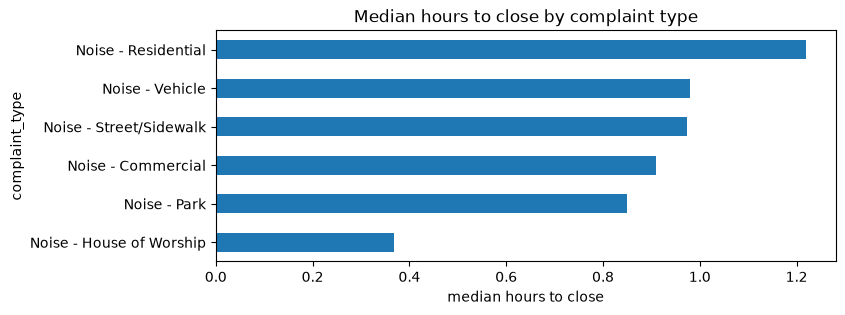

In [11]:
_ = a.plot_median_by(by_type, "Median hours to close by complaint type")

**نتیجه:** شکایت‌های «Noise - Residential» کندترین‌اند (میانه حدود ۱٫۲۲ ساعت) و «House of Worship» سریع‌ترین (حدود ۰٫۳۷ ساعت، فقط ۴٬۷۲۶ پرونده).
تفاوت نوع‌ها قابل‌توجه است و حدود سه برابر.

In [12]:
by_borough = a.median_by(df, "borough")
by_borough.round(3)

,median,count
borough,,
BRONX,1.552,355803
STATEN ISLAND,1.095,23560
QUEENS,1.092,208455
BROOKLYN,0.932,269873
MANHATTAN,0.881,225668


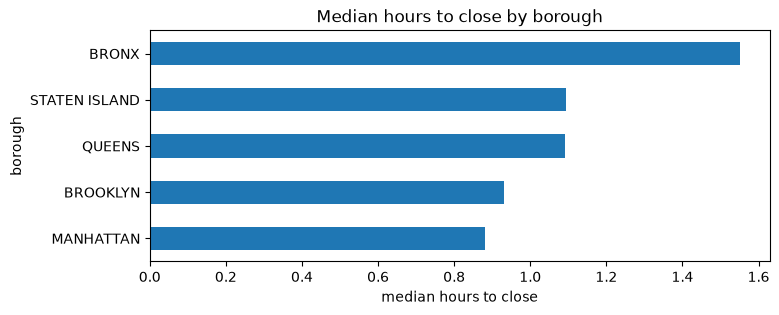

In [13]:
_ = a.plot_median_by(by_borough, "Median hours to close by borough")

**نتیجه:** برانکس کندترین بخش است (میانه حدود ۱٫۵۵ ساعت) و منهتن سریع‌ترین (حدود ۰٫۸۸ ساعت).
این یک مقایسه‌ی توصیفی است و علت آن (تعداد مأمور، حجم شکایت، نوع شکایت) را نشان نمی‌دهد.

## ۴. روند در طول زمان

**چه چیزی را می‌سنجیم:** میانه‌ی ماهانه‌ی مدت بستن بر اساس ماه ثبت.

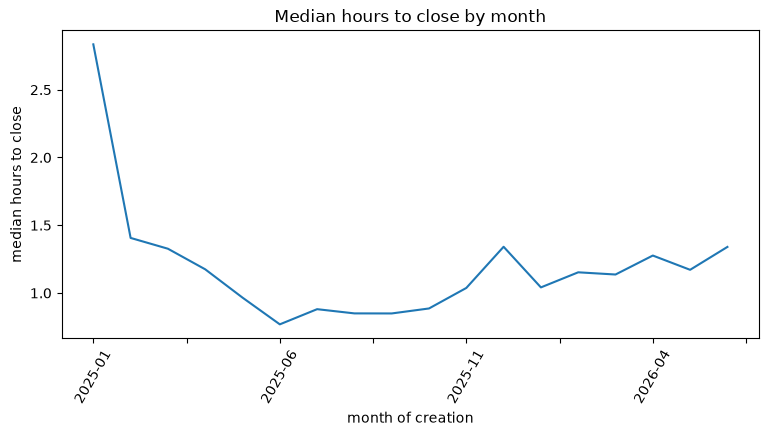

In [14]:
trend = a.monthly_median(df)
_ = a.plot_monthly_trend(trend, "Median hours to close by month")

In [15]:
trend.round(3)

month
2025-01    2.835
2025-02    1.406
2025-03    1.327
2025-04    1.175
2025-05    0.966
2025-06    0.769
2025-07    0.881
2025-08    0.849
2025-09    0.849
2025-10    0.886
2025-11    1.037
2025-12    1.341
2026-01    1.041
2026-02    1.153
2026-03    1.136
2026-04    1.276
2026-05    1.171
2026-06    1.340
Name: duration_hours, dtype: float64

**نتیجه:** میانه در ژانویه ۲۰۲۵ بالاترین مقدار را دارد (حدود ۲٫۸ ساعت)، تا ژوئن ۲۰۲۵ به حدود ۰٫۷۷ ساعت می‌رسد و دوباره تا حدود ۱٫۳ ساعت در دسامبر ۲۰۲۵ و ژوئن ۲۰۲۶ بالا می‌رود.

**محدودیت (فرض):** اگر فایل فقط پرونده‌های بسته‌شده را دارد، ماه‌های آخر ممکن است کوتاه‌تر از واقع به نظر برسند، چون پرونده‌های کند هنوز بسته نشده‌اند.
این اثر در این نوت‌بوک اندازه‌گیری نشده و باید جداگانه بررسی شود.

## ۵. نرخ شکایت نسبت به جمعیت منطقه

**چرا نرخ:** تعداد خام شکایت بین منطقه‌ی کوچک و پرجمعیت قابل‌مقایسه نیست؛ مخرج جمعیتی لازم است.
رکوردهای بدون منطقه یا جمعیت از این جدول کنار گذاشته می‌شوند.

In [16]:
rates = a.area_rates(df)
top = rates.head(10).round(2)
top

,complaints,population,per_10k
modzcta,,,
10466,134803,72479.0,18598.90
11366,11370,14650.0,7761.09
10004,1461,3028.0,4824.97
10030,7837,29882.0,2622.65
10040,11631,44571.0,2609.54
10031,15593,60254.0,2587.88
10026,10002,39363.0,2540.96
10034,10792,42910.0,2515.03
10456,23609,94218.0,2505.78


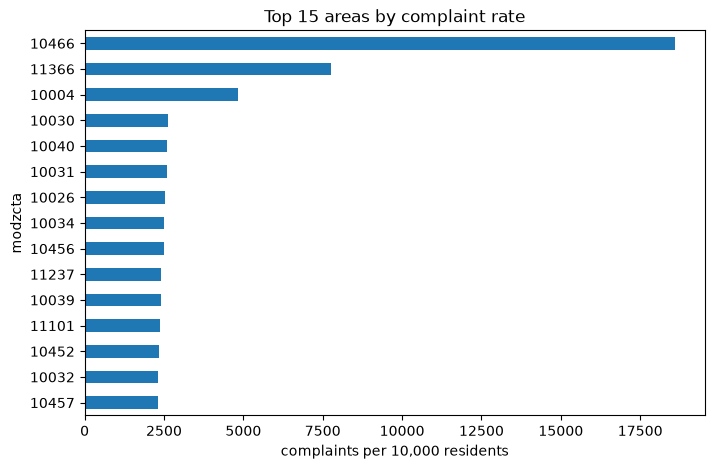

In [17]:
_ = a.plot_area_rates(rates)

In [18]:
leader = rates.iloc[0]
{
    "zip": rates.index[0],
    "complaints": int(leader["complaints"]),
    "share_of_all_cases": round(leader["complaints"] / len(df), 4),
    "second_per_10k": round(rates.iloc[1]["per_10k"], 1),
}

{'zip': np.int64(10466),
 'complaints': 134803,
 'share_of_all_cases': np.float64(0.1244),
 'second_per_10k': np.float64(7761.1)}

**نتیجه:** منطقه‌ی 10466 با ۱۳۴٬۸۰۳ شکایت برای ۷۲٬۴۷۹ نفر، نرخ حدود ۱۸٬۵۹۹ در ده‌هزار نفر دارد؛ یعنی بیش از یک شکایت به‌ازای هر نفر، و حدود ۱۲٫۴٪ کل پرونده‌ها.
نفر دوم (11366) حدود ۷٬۷۶۱ است، پس 10466 حدود ۲٫۴ برابر منطقه‌ی بعدی است.

**فرض (اندازه‌گیری‌نشده):** این مقدار احتمالاً از شاکی‌های تکراری یا یک آدرس پرتکرار می‌آید. این فرض را نمی‌توان با ستون‌های موجود تأیید کرد و باید با ستون آدرس داده‌ی خام بررسی شود.
این را یک یافته‌ی کیفیت داده می‌دانیم، نه یک نتیجه‌ی رفتاری درباره‌ی ساکنان آن منطقه.

مناطق با جمعیت بسیار کم (مثل 10004 با ۳٬۰۲۸ نفر) هم نرخ ناپایدار دارند، چون مخرج کوچک است.

## ۶. الگوی ساعت و روز هفته

**چه چیزی را می‌سنجیم:** تعداد شکایت‌ها در هر ساعت و روز هفته.

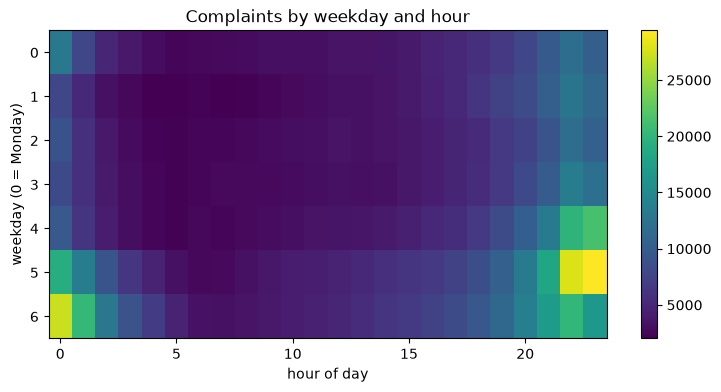

In [19]:
counts = a.hour_weekday_counts(df)
_ = a.plot_hour_weekday(counts)

In [20]:
hourly = counts.sum()
night_hours = [21, 22, 23, 0, 1]
{
    "peak_hour": int(hourly.idxmax()),
    "peak_count": int(hourly.max()),
    "low_hour": int(hourly.idxmin()),
    "low_count": int(hourly.min()),
    "night_share_21_to_01": round(hourly[night_hours].sum() / hourly.sum(), 4),
}

{'peak_hour': 22,
 'peak_count': 117772,
 'low_hour': 7,
 'low_count': 18266,
 'night_share_21_to_01': np.float64(0.4385)}

**نتیجه:** اوج شکایت‌ها ساعت ۲۲ است و کمترین مقدار حدود ساعت ۶ تا ۷. ساعت‌های ۲۱ تا ۱ بامداد حدود ۴۳٫۸٪ کل شکایت‌ها را دارند.

## ۷. رابطه‌ی متغیرهای عددی

**روش:** همبستگی Spearman (رتبه‌ای)، چون مدت بستن چوله است. برای سرعت روی نمونه‌ی ۲۰۰٬۰۰۰ تایی با seed ثابت محاسبه می‌شود.

In [21]:
a.spearman(df).round(3)

,duration_hours,population,hour,weekday
duration_hours,1.000,0.061,0.011,-0.020
population,0.061,1.000,-0.005,0.006
hour,0.011,-0.005,1.000,-0.038
weekday,-0.020,0.006,-0.038,1.000


**نتیجه:** همه‌ی ضریب‌ها ضعیف‌اند و بزرگ‌ترین قدر مطلق ۰٫۰۶۱ است (مدت و جمعیت). ساعت ثبت، روز هفته و جمعیت منطقه به‌تنهایی مدت بستن را توضیح نمی‌دهند.

## ۸. یافته‌های غیربدیهی و محدودیت‌ها

**یافته‌ها**

1. یک منطقه (10466) به‌تنهایی حدود ۱۲٫۴٪ کل پرونده‌ها را دارد و نرخش حدود ۲٫۴ برابر منطقه‌ی دوم است؛ این یک نکته‌ی کیفیت داده است که تحلیل‌های بعدی باید حساب کنند.
2. کندی مدت بستن به نوع و محل شکایت بسته است (برانکس و شکایت‌های مسکونی کندترند) نه به ساعت یا روز هفته؛ ضریب‌های Spearman نزدیک صفرند.
3. شکایت‌ها شبانه متمرکزند (حدود ۴۳٫۸٪ بین ساعت ۲۱ و ۱) ولی مدت بستن تقریباً به ساعت ثبت وابسته نیست.

**محدودیت‌ها**

- میانه فقط رفتار مرکزی را نشان می‌دهد و علت را توضیح نمی‌دهد.
- اثر احتمالی پرونده‌های بازِ ماه‌های آخر روی روند اندازه‌گیری نشده است.
- علت تمرکز شکایت در 10466 فرض است و تأیید نشده.
- همبستگی Spearman فقط وابستگی یکنوا را می‌سنجد.